# Linear Discriminant Analysis Workflow

This notebook runs Linear Discriminant Analysis (LDA) for dietary classification using mandibular second molar shape data.

It is written as a repository-ready version of the original LDA workflow so that readers can download `Example_Data.csv` or use the GPA output and run the analysis themselves.

## What this notebook does

1. Loads Procrustes-aligned coordinate data.
2. Detects coordinate columns named `X1`, `Y1`, ..., `X23`, `Y23`.
3. Uses dietary category as the classification target.
4. Splits the data into stratified training and held-out test sets.
5. Uses a scikit-learn `Pipeline` to combine scaling, PCA, and LDA.
6. Utilizes LOOCV cross-validation to select the lowest number of PCs that achieve the highest cross-         validated accuracy. 
7. Evaluates LDA using cross-validation on the training data and final performance on the held-out test set.
8. Saves performance metrics, classification reports, confusion matrices, learning curves, PCA summaries, and misclassified specimens.

## Important note for non-machine learning readers

The PCA step is inside the scikit-learn `Pipeline`. This means that PCA is fit only on the training data within each cross-validation fold, rather than being fit once using the entire dataset. This avoids data leakage.

The held-out test set is not used during cross-validation. It is used only once at the end for final model evaluation.


## 1. Edit file paths and analysis settings

The preferred input is the Procrustes-aligned coordinate file produced by the GPA notebook:

```python
INPUT_FILE = Path("../../results/gpa/procrustes_aligned_coordinates.csv")
```

For the full manuscript workflow, run the GPA notebook first, then run this LDA notebook.

By default, LDA uses the number of principal components selected using leave-one-out cross-validation within the training subset. Sequential models containing increasing numbers of PCs are evaluated, and the number producing the highest LOOCV accuracy is retained. When multiple models achieve the same accuracy, the model containing fewer PCs is selected.

In [ ]:
# -----------------------------
# Editable settings
# -----------------------------

from pathlib import Path

# Preferred input:
# Use the Procrustes-aligned coordinates produced by the GPA notebook.
#INPUT_FILE = Path("../../results/gpa/procrustes_aligned_coordinates.csv")
INPUT_FILE = Path('# INSERT FILE PATH TO PROCRUSTES ALIGNED COORDINATES HERE (OUTPUT FROM GPA)')


# Folder where LDA outputs will be saved.
OUTPUT_DIR = Path("../../results/lda")

# Dietary category column.
# In the manuscript dataset, Column1 contains the dietary category labels.
TARGET_COLUMN = "Column1"

# Metadata columns to carry into misclassification outputs if present.
METADATA_COLUMNS = ["Species", "Tribe", "File_Name"]

MAX_PCS_TO_TEST = None

# analysis settings.
TEST_SIZE = 0.30
RANDOM_STATE = 42

# Number of folds for cross-validation.
# The notebook will automatically reduce this if a class has fewer specimens than N_SPLITS.
N_SPLITS = 5

# Create output folder if it does not already exist.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Primary input file: {INPUT_FILE}")
print(f"Output folder: {OUTPUT_DIR}")
print(f"Target column: {TARGET_COLUMN}")
#print(f"PCA components used before LDA: {PCA_N_COMPONENTS}")


## 2. Import packages and define helper functions

In [5]:
# -----------------------------
# Imports and helper functions
# -----------------------------

from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Iterable, List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    LeaveOneOut,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer


def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    """
    Remove whitespace and invisible characters from column names.

    This helps prevent errors caused by CSV files exported from spreadsheets.
    """
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.replace(r"\s+", "", regex=True)
        .str.replace("\ufeff", "", regex=False)
    )
    return df


def coordinate_sort_key(column_name: str) -> tuple[int, int]:
    """
    Sort coordinate columns in anatomical order:
    X1, Y1, X2, Y2, ..., X23, Y23.
    """
    match = re.fullmatch(r"([XY])(\d+)", column_name)
    if match is None:
        return (10_000, 10_000)

    axis, number = match.groups()
    axis_order = 0 if axis == "X" else 1
    return (int(number), axis_order)


def find_coordinate_columns(df: pd.DataFrame) -> List[str]:
    """
    Detect coordinate columns named X1, Y1, X2, Y2, etc.
    """
    coordinate_columns = [
        col for col in df.columns
        if re.fullmatch(r"[XY]\d+", str(col))
    ]
    coordinate_columns = sorted(coordinate_columns, key=coordinate_sort_key)

    if len(coordinate_columns) == 0:
        raise ValueError(
            "No coordinate columns were found. Expected columns named like "
            "X1, Y1, X2, Y2, ..., X23, Y23."
        )

    if len(coordinate_columns) % 2 != 0:
        raise ValueError(
            f"Found {len(coordinate_columns)} coordinate columns, which is not even. "
            "Each landmark should have both an X and a Y coordinate."
        )

    return coordinate_columns


def ensure_numeric_coordinates(df: pd.DataFrame, coordinate_columns: Iterable[str]) -> pd.DataFrame:
    """
    Convert coordinate columns to numeric values and stop clearly if conversion fails.
    """
    coords = df[list(coordinate_columns)].copy()

    for col in coords.columns:
        coords[col] = pd.to_numeric(coords[col], errors="coerce")

    missing_counts = coords.isna().sum()
    problematic = missing_counts[missing_counts > 0]

    if not problematic.empty:
        raise ValueError(
            "Some coordinate columns contain missing or non-numeric values:\n"
            + problematic.to_string()
            + "\nPlease check the input CSV."
        )

    return coords


def choose_cv_splits(y: np.ndarray, requested_splits: int) -> int:
    """
    Choose a safe number of cross-validation folds.

    Stratified cross-validation requires each class to have at least as many
    specimens as the number of folds.
    """
    class_counts = pd.Series(y).value_counts()
    min_class_count = int(class_counts.min())
    safe_splits = min(requested_splits, min_class_count)

    if safe_splits < 2:
        raise ValueError(
            "At least one class has fewer than 2 specimens. "
            "Stratified cross-validation cannot be performed."
        )

    if safe_splits < requested_splits:
        print(
            f"Requested {requested_splits} CV folds, but the smallest class has "
            f"only {min_class_count} specimens. Using {safe_splits} folds instead."
        )

    return safe_splits


def calculate_multiclass_roc_auc(
    y_true: np.ndarray,
    y_probability: np.ndarray,
    class_labels: np.ndarray,
) -> float:
    """
    Calculate one-vs-rest multiclass ROC AUC.

    Returns NaN if ROC AUC cannot be calculated.
    """
    try:
        y_true_binarized = label_binarize(y_true, classes=class_labels)

        if y_true_binarized.shape[1] == 1:
            return roc_auc_score(y_true_binarized, y_probability[:, 1])

        return roc_auc_score(
            y_true_binarized,
            y_probability,
            average="macro",
            multi_class="ovr",
        )
    except Exception as error:
        print(f"ROC AUC could not be calculated: {error}")
        return np.nan


def save_json(obj: dict, path: Path) -> None:
    """
    Save a dictionary to JSON.
    """
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
    print(f"Saved: {path}")


## 3. Load and validate the dataset

This cell loads the input CSV, detects coordinate columns, checks the dietary category column, and encodes diet labels as numbers for scikit-learn.

The original diet labels are preserved and saved in the output files.


In [ ]:
# -----------------------------
# Load and validate input data
# -----------------------------

if INPUT_FILE.exists():
    data_file = INPUT_FILE
    print(f"Using primary input file: {data_file}")
else:
    raise FileNotFoundError(
        "Primary Input file not found.\n"
        f"Primary: {INPUT_FILE}\n"
    )

data = pd.read_csv(data_file)
data = clean_column_names(data)

print(f"Loaded {data.shape[0]} specimens and {data.shape[1]} columns.")

if TARGET_COLUMN not in data.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' was not found. "
        f"Available columns are: {list(data.columns)}"
    )

coordinate_columns = find_coordinate_columns(data)
X = ensure_numeric_coordinates(data, coordinate_columns)

# Remove rows with missing target labels.
valid_target_mask = data[TARGET_COLUMN].notna()
if not valid_target_mask.all():
    n_removed = int((~valid_target_mask).sum())
    print(f"Removing {n_removed} rows with missing target labels.")
    data = data.loc[valid_target_mask].reset_index(drop=True)
    X = X.loc[valid_target_mask].reset_index(drop=True)

# Encode diet labels as integers for scikit-learn.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data[TARGET_COLUMN].astype(str))

label_mapping = {
    int(i): label
    for i, label in enumerate(label_encoder.classes_)
}

print("\nDiet label mapping:")
for numeric_label, original_label in label_mapping.items():
    print(f"{numeric_label}: {original_label}")

metadata_columns_present = [col for col in METADATA_COLUMNS if col in data.columns]

print(f"\nDetected {len(coordinate_columns)} coordinate columns.")
print(f"This corresponds to {len(coordinate_columns) // 2} landmarks.")
print(f"Metadata columns available for misclassification summaries: {metadata_columns_present}")
print("\nClass counts:")
display(data[TARGET_COLUMN].value_counts().rename("count").to_frame())


## 4. Plot dietary class distribution

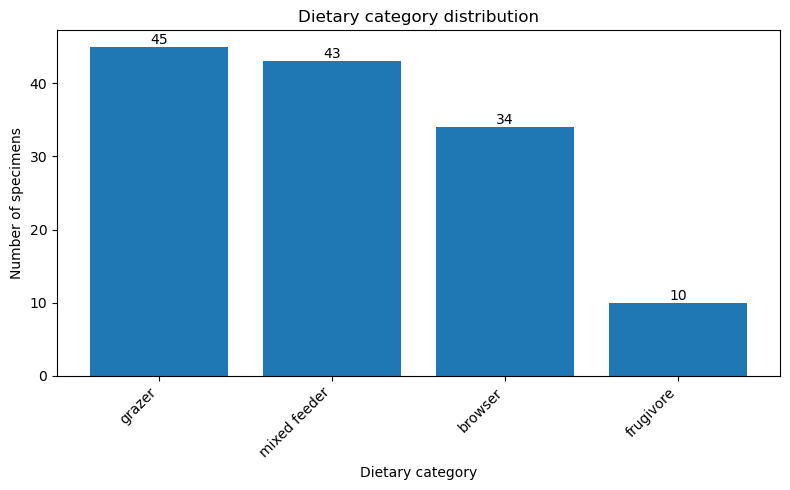

Saved: ../../results/lda/lda_class_distribution.png


In [11]:
# -----------------------------
# Plot class distribution
# -----------------------------

class_counts = data[TARGET_COLUMN].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Dietary category distribution")
plt.xlabel("Dietary category")
plt.ylabel("Number of specimens")
plt.xticks(rotation=45, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
class_plot_path = OUTPUT_DIR / "lda_class_distribution.png"
plt.savefig(class_plot_path, dpi=300)
plt.show()
print(f"Saved: {class_plot_path}")


## 5. Create stratified train/test split and LDA pipeline

The pipeline is:

```text
StandardScaler → PCA → LinearDiscriminantAnalysis
```


In [13]:
# -----------------------------
# Stratified train/test split and LDA pipeline
# -----------------------------

# A stratified split preserves the relative frequency of each dietary category
# in both the training and test sets.
#
# The training set is used for cross-validation.
# The held-out test set is used only once for final model evaluation.

X_train, X_test, y_train, y_test, train_indices, test_indices = train_test_split(
    X,
    y,
    data.index.to_numpy(),
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv_splits = choose_cv_splits(y_train, N_SPLITS)

cv = StratifiedKFold(
    n_splits=cv_splits,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Pipeline explanation:
#
# 1. StandardScaler:
#    Standardizes each coordinate variable using only the training data.
#
# 2. PCA:
#    Converts Procrustes coordinates into principal component scores.
#    PCA selection utilizes LOOCV to cross-validate and select best number of
#    components. If there is equal cross-validated accuracy. The cross-validated 
#    accuracy with the lowest number of PCs wins. 
#
# 3. LinearDiscriminantAnalysis:
#    Fits the LDA classifier using the selected PC scores.
#
# Because scaling and PCA are inside the Pipeline, they are fit only on the
# training fold during cross-validation. This prevents data leakage.
# -----------------------------
# Select number of PCs using leave-one-out cross-validation
# -----------------------------

# The PC count is selected using the training set only.
# Each candidate model uses:
# StandardScaler -> PCA -> LDA
#
# PCA is refitted inside every leave-one-out fold, preventing data leakage.

loo = LeaveOneOut()

# PCA cannot retain more components than the number of coordinate variables
# or the number of observations available in each LOOCV training fold.
max_allowable_pcs = min(
    X_train.shape[1],
    X_train.shape[0] - 2,
)

if MAX_PCS_TO_TEST is not None:
    max_allowable_pcs = min(max_allowable_pcs, MAX_PCS_TO_TEST)

if max_allowable_pcs < 1:
    raise ValueError(
        "Too few training observations or coordinate variables to evaluate PCA."
    )

pc_selection_rows = []

for n_pcs in range(1, max_allowable_pcs + 1):

    candidate_pipeline = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n_pcs)),
            ("lda", LinearDiscriminantAnalysis()),
        ]
    )

    loo_scores = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        cv=loo,
        scoring="accuracy",
        n_jobs=-1,
    )

    pc_selection_rows.append(
        {
            "n_pcs": n_pcs,
            "loocv_accuracy": float(np.mean(loo_scores)),
            "correctly_classified": int(np.sum(loo_scores)),
            "n_training_specimens": int(len(loo_scores)),
        }
    )

pc_selection_df = pd.DataFrame(pc_selection_rows)

# Select the highest LOOCV accuracy.
best_accuracy = pc_selection_df["loocv_accuracy"].max()

# When multiple PC counts tie, retain the smaller model.
SELECTED_N_PCS = int(
    pc_selection_df.loc[
        pc_selection_df["loocv_accuracy"] == best_accuracy,
        "n_pcs",
    ].min()
)

print("Leave-one-out PC selection")
print("--------------------------")
print(f"PC counts evaluated: 1 to {max_allowable_pcs}")
print(f"Selected number of PCs: {SELECTED_N_PCS}")
print(f"Best LOOCV accuracy: {best_accuracy:.3f}")

display(pc_selection_df)


lda_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=SELECTED_N_PCS)),
        ("lda", LinearDiscriminantAnalysis()),
    ]
)

print(f"Training specimens: {X_train.shape[0]}")
print(f"Test specimens: {X_test.shape[0]}")
print(f"Cross-validation folds: {cv_splits}")
print(f"LDA will use PCA_N_COMPONENTS = {SELECTED_N_PCS}")

Leave-one-out PC selection
--------------------------
PC counts evaluated: 1 to 46
Selected number of PCs: 6
Best LOOCV accuracy: 0.467


,n_pcs,loocv_accuracy,correctly_classified,n_training_specimens
0,1,0.413043,38,92
1,2,0.413043,38,92
2,3,0.434783,40,92
3,4,0.402174,37,92
4,5,0.369565,34,92
5,6,0.467391,43,92
6,7,0.456522,42,92
7,8,0.445652,41,92
8,9,0.413043,38,92
9,10,0.413043,38,92


Training specimens: 92
Test specimens: 40
Cross-validation folds: 5
LDA will use PCA_N_COMPONENTS = 6


In [14]:
# Save the PC-selection results 
pc_selection_path = OUTPUT_DIR / "lda_loocv_pc_selection.csv"
pc_selection_df.to_csv(pc_selection_path, index=False)

print(f"Saved: {pc_selection_path}")

Saved: ../../results/lda/lda_loocv_pc_selection.csv


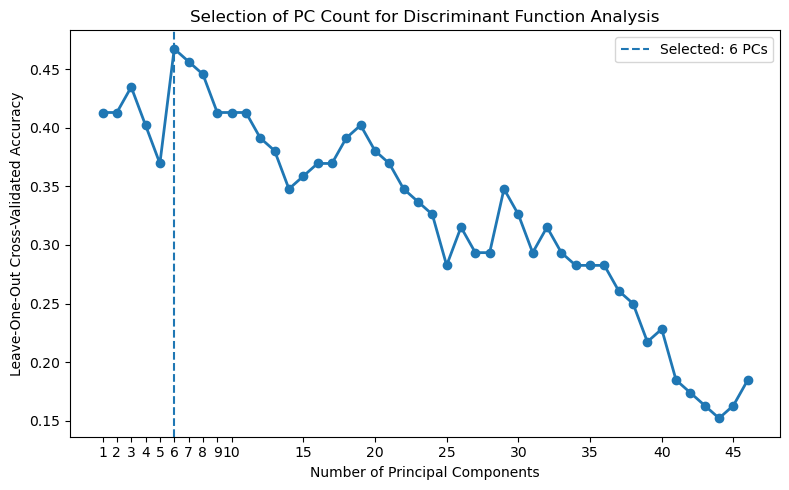

Saved: ../../results/lda/lda_loocv_pc_selection.png


In [16]:
# -----------------------------
# Plot LOOCV accuracy by number of PCs
# -----------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    pc_selection_df["n_pcs"],
    pc_selection_df["loocv_accuracy"],
    marker="o",
    linewidth=2,
)

plt.axvline(
    SELECTED_N_PCS,
    linestyle="--",
    label=f"Selected: {SELECTED_N_PCS} PCs",
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Leave-One-Out Cross-Validated Accuracy")
plt.title("Selection of PC Count for Discriminant Function Analysis")
# First 10 PCs labelled individually (1,2,...,10), then every 5th.
_all_pcs = pc_selection_df["n_pcs"].tolist()
_tick_positions = [n for n in _all_pcs if n <= 10 or n % 5 == 0]
_tick_labels = [str(n) for n in _tick_positions]
plt.xticks(_tick_positions, _tick_labels)
plt.legend()
plt.tight_layout()

pc_selection_figure_path = (
    OUTPUT_DIR / "lda_loocv_pc_selection.png"
)

plt.savefig(
    pc_selection_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved: {pc_selection_figure_path}")

## 6. Run cross-validation and final test-set evaluation

Cross-validation is performed on the training set only. The held-out test set is evaluated after the final LDA pipeline is fit to the full training set.


In [18]:
# -----------------------------
# Cross-validation on training data and final test-set evaluation
# -----------------------------

# Cross-validation estimates model stability using the training data only.
cv_scores = cross_val_score(
    lda_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)

# Fit the final model on the full training set.
lda_pipeline.fit(X_train, y_train)

# Predict on the training and held-out test sets.
y_train_pred = lda_pipeline.predict(X_train)
y_test_pred = lda_pipeline.predict(X_test)

# LDA can provide class probabilities, which are used for ROC AUC.
y_test_probability = lda_pipeline.predict_proba(X_test)

class_labels = np.arange(len(label_encoder.classes_))

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
balanced_acc = balanced_accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_test_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)
roc_auc = calculate_multiclass_roc_auc(y_test, y_test_probability, class_labels)

conf_matrix = confusion_matrix(y_test, y_test_pred, labels=class_labels)

classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        labels=class_labels,
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).transpose()

lda_results = {
    "model": "Linear Discriminant Analysis",
    "pca_n_components": SELECTED_N_PCS,
    "pc_selection_method": "leave-one-out cross validation",
    "pc_selection_loocv_accuracy": float(best_accuracy),
    "cv_mean_accuracy": float(np.mean(cv_scores)),
    "cv_sd_accuracy": float(np.std(cv_scores)),
    "train_accuracy": float(train_accuracy),
    "test_accuracy": float(test_accuracy),
    "balanced_accuracy": float(balanced_acc),
    "precision_weighted": float(precision),
    "recall_weighted": float(recall),
    "f1_weighted": float(f1),
    "roc_auc_macro_ovr": float(roc_auc) if not np.isnan(roc_auc) else np.nan,
    "n_train": int(len(y_train)),
    "n_test": int(len(y_test)),
    "cv_folds": int(cv_splits),
}

print("LDA performance summary")
print("-----------------------")
for key, value in lda_results.items():
    print(f"{key}: {value}")

display(classification_report_df)


LDA performance summary
-----------------------
model: Linear Discriminant Analysis
pca_n_components: 6
pc_selection_method: leave-one-out cross validation
pc_selection_loocv_accuracy: 0.4673913043478261
cv_mean_accuracy: 0.41345029239766085
cv_sd_accuracy: 0.058233400161425045
train_accuracy: 0.5652173913043478
test_accuracy: 0.325
balanced_accuracy: 0.26043956043956046
precision_weighted: 0.3277972027972028
recall_weighted: 0.325
f1_weighted: 0.32605820105820105
roc_auc_macro_ovr: 0.5608005808005808
n_train: 92
n_test: 40
cv_folds: 5


,precision,recall,f1-score,support
browser,0.272727,0.300000,0.285714,10.000
frugivore,0.000000,0.000000,0.000000,3.000
grazer,0.384615,0.357143,0.370370,14.000
mixed feeder,0.384615,0.384615,0.384615,13.000
accuracy,0.325000,0.325000,0.325000,0.325
macro avg,0.260490,0.260440,0.260175,40.000
weighted avg,0.327797,0.325000,0.326058,40.000


Using 'ln_centroid_size_mm' as the centroid size column for the shape+size model.
Shape-only vs. Shape + centroid size
------------------------------------


,model,n_pcs,cv_mean_accuracy,cv_std_accuracy,train_accuracy,test_accuracy,test_balanced_accuracy,test_precision_weighted,test_recall_weighted,test_f1_weighted,test_roc_auc_macro_ovr,delta_vs_shape_only
0,Shape only (Procrustes coordinates),6,0.413450,0.058233,0.565217,0.325,0.260440,0.327797,0.325,0.326058,0.560801,0.000
1,"Shape + centroid size (ln, mm-calibrated)",6,0.445614,0.063109,0.597826,0.350,0.278297,0.349405,0.350,0.349318,0.588328,0.025



Saved: ../../results/lda/lda_shape_vs_shape_cs_comparison.csv


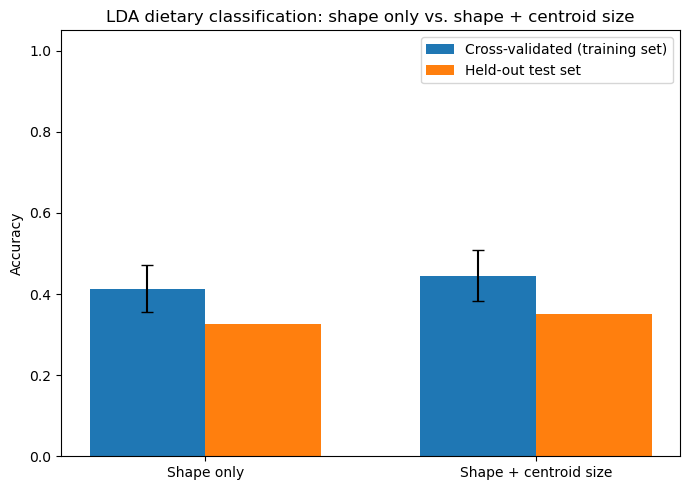

Saved: ../../results/lda/lda_shape_vs_shape_cs_comparison.png


In [19]:
# -----------------------------
# Shape vs. Shape + Centroid Size (does adding size improve LDA?)
# -----------------------------
#
# This cell answers a specific question: does adding centroid size (calculated
# from the RAW, pre-Procrustes landmark coordinates, calibrated to real-world
# mm units, and natural-log transformed) improve dietary classification
# accuracy relative to using the Procrustes shape coordinates alone?
#
# Design choices, to keep this an apples-to-apples comparison with the
# shape-only LDA model fit above:
#   - The SAME train/test split (X_train/X_test, y_train/y_test) is reused.
#   - The SAME number of PCs (SELECTED_N_PCS) is reused for the shape part of
#     the shape+size model, so any accuracy change reflects the addition of
#     centroid size rather than a different PC count.
#   - PCA is fit only on the shape (coordinate) columns; centroid size is
#     scaled but not projected through PCA, then both are passed to LDA.
#   - The SAME cross-validation splitter (`cv`) and held-out test set are
#     reused, so cross-validated and test-set accuracy are directly comparable
#     to the shape-only results computed above.

# The GPA notebook may export this column as "ln_centroid_size_mm" (if it
# computed it fresh from a raw mm-per-pixel scale factor) or under whatever
# name it already had in your raw data (e.g. "Ln_Centroid_Size_mm") if it was
# already precomputed and simply passed through. Match either way, ignoring
# case/spacing/punctuation differences.
def _normalize_column_name(name: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

_cs_aliases = [
    "ln_centroid_size_mm", "ln centroid size mm", "log_centroid_size_mm",
    "logcentroidsizemm", "lncsmm",
]
_normalized_lookup = {_normalize_column_name(col): col for col in data.columns}
_matched_cs_column = None
for alias in _cs_aliases:
    normalized_alias = _normalize_column_name(alias)
    if normalized_alias in _normalized_lookup:
        _matched_cs_column = _normalized_lookup[normalized_alias]
        break

if _matched_cs_column is None:
    raise ValueError(
        "No ln(centroid size, mm-calibrated) column was found in the loaded "
        f"data. Available columns: {list(data.columns)}\n"
        "Run the updated GPA notebook first -- it carries this column through "
        "to procrustes_aligned_coordinates.csv either by passing through a "
        "precomputed column from your raw data, or by computing it from a "
        "raw mm-per-pixel scale factor."
    )

CS_COLUMN = _matched_cs_column
print(f"Using '{CS_COLUMN}' as the centroid size column for the shape+size model.")

# Build shape+CS feature tables aligned to the same train/test rows already
# used for the shape-only model above.
X_train_cs = X_train.copy()
X_train_cs[CS_COLUMN] = data.loc[X_train.index, CS_COLUMN].to_numpy()

X_test_cs = X_test.copy()
X_test_cs[CS_COLUMN] = data.loc[X_test.index, CS_COLUMN].to_numpy()

# Shape + centroid size pipeline:
# PCA is applied only to the shape (coordinate) columns; centroid size gets
# its own standardization and is passed to LDA alongside the PC scores.
shape_cs_preprocessor = ColumnTransformer(
    transformers=[
        (
            "shape",
            Pipeline(
                steps=[
                    ("scaler", StandardScaler()),
                    ("pca", PCA(n_components=SELECTED_N_PCS)),
                ]
            ),
            coordinate_columns,
        ),
        (
            "size",
            StandardScaler(),
            [CS_COLUMN],
        ),
    ]
)

shape_cs_pipeline = Pipeline(
    steps=[
        ("preprocessor", shape_cs_preprocessor),
        ("lda", LinearDiscriminantAnalysis()),
    ]
)

# Cross-validated accuracy on the training data, using the same CV splitter
# used for the shape-only model.
shape_cs_cv_scores = cross_val_score(
    shape_cs_pipeline,
    X_train_cs,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)


# Fit on the full training set and evaluate once on the held-out test set.
shape_cs_pipeline.fit(X_train_cs, y_train)

# --- Training accuracy (added) ---
y_train_pred_cs = shape_cs_pipeline.predict(X_train_cs)
train_accuracy_cs = accuracy_score(y_train, y_train_pred_cs)

y_test_pred_cs = shape_cs_pipeline.predict(X_test_cs)
y_test_probability_cs = shape_cs_pipeline.predict_proba(X_test_cs)

test_accuracy_cs = accuracy_score(y_test, y_test_pred_cs)
balanced_acc_cs = balanced_accuracy_score(y_test, y_test_pred_cs)
precision_cs = precision_score(y_test, y_test_pred_cs, average="weighted", zero_division=0)
recall_cs = recall_score(y_test, y_test_pred_cs, average="weighted", zero_division=0)
f1_cs = f1_score(y_test, y_test_pred_cs, average="weighted", zero_division=0)
roc_auc_cs = calculate_multiclass_roc_auc(y_test, y_test_probability_cs, class_labels)

conf_matrix_cs = confusion_matrix(y_test, y_test_pred_cs, labels=class_labels)

# -----------------------------
# Also re-run the SAME shape-only pipeline on this cell's CV splitter for a
# clean side-by-side comparison table (reuses cv_scores/test_accuracy already
# computed above from the main shape-only model; no need to refit).
# -----------------------------

# --- Training accuracy for shape-only model (added) ---
y_train_pred_shape = lda_pipeline.predict(X_train)
train_accuracy_shape = accuracy_score(y_train, y_train_pred_shape)

comparison_df = pd.DataFrame(
    [
        {
            "model": "Shape only (Procrustes coordinates)",
            "n_pcs": SELECTED_N_PCS,
            "cv_mean_accuracy": float(np.mean(cv_scores)),
            "cv_std_accuracy": float(np.std(cv_scores)),
            "train_accuracy": float(train_accuracy),
            "test_accuracy": float(test_accuracy),
            "test_balanced_accuracy": float(balanced_acc),
            "test_precision_weighted": float(precision),
            "test_recall_weighted": float(recall),
            "test_f1_weighted": float(f1),
            "test_roc_auc_macro_ovr": float(roc_auc) if roc_auc == roc_auc else np.nan,
        },
        {
            "model": "Shape + centroid size (ln, mm-calibrated)",
            "n_pcs": SELECTED_N_PCS,
            "cv_mean_accuracy": float(np.mean(shape_cs_cv_scores)),
            "cv_std_accuracy": float(np.std(shape_cs_cv_scores)),
            "train_accuracy": float(train_accuracy_cs),
            "test_accuracy": float(test_accuracy_cs),
            "test_balanced_accuracy": float(balanced_acc_cs),
            "test_precision_weighted": float(precision_cs),
            "test_recall_weighted": float(recall_cs),
            "test_f1_weighted": float(f1_cs),
            "test_roc_auc_macro_ovr": float(roc_auc_cs) if roc_auc_cs == roc_auc_cs else np.nan,
        },
    ]
)

comparison_df["delta_vs_shape_only"] = (
    comparison_df["test_accuracy"] - comparison_df.loc[0, "test_accuracy"]
)

print("Shape-only vs. Shape + centroid size")
print("------------------------------------")
display(comparison_df)

comparison_path = OUTPUT_DIR / "lda_shape_vs_shape_cs_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)
print(f"\nSaved: {comparison_path}")

# Bar chart comparing cross-validated and held-out test accuracy for both models.
plt.figure(figsize=(7, 5))
x_pos = np.arange(2)
width = 0.35

plt.bar(
    x_pos - width / 2,
    comparison_df["cv_mean_accuracy"],
    width,
    yerr=comparison_df["cv_std_accuracy"],
    label="Cross-validated (training set)",
    capsize=4,
)
plt.bar(
    x_pos + width / 2,
    comparison_df["test_accuracy"],
    width,
    label="Held-out test set",
)

plt.xticks(x_pos, ["Shape only", "Shape + centroid size"])
plt.ylabel("Accuracy")
plt.title("LDA dietary classification: shape only vs. shape + centroid size")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

comparison_plot_path = OUTPUT_DIR / "lda_shape_vs_shape_cs_comparison.png"
plt.savefig(comparison_plot_path, dpi=300)
plt.show()
print(f"Saved: {comparison_plot_path}")


## 7. Extract PCA information from the fitted LDA pipeline

In [21]:
# -----------------------------
# Extract PCA information from the fitted pipeline
# -----------------------------

# This PCA object was fit on the full training set as part of the final LDA pipeline.
# It is used here only for reporting the variance explained by the PCs used in LDA.

fitted_pca = lda_pipeline.named_steps["pca"]

pc_names = [f"PC{i + 1}" for i in range(fitted_pca.n_components_)]

pca_variance_df = pd.DataFrame({
    "PC": pc_names,
    "explained_variance": fitted_pca.explained_variance_,
    "explained_variance_ratio": fitted_pca.explained_variance_ratio_,
    "explained_variance_percent": fitted_pca.explained_variance_ratio_ * 100,
    "cumulative_explained_variance_ratio": np.cumsum(fitted_pca.explained_variance_ratio_),
    "cumulative_explained_variance_percent": np.cumsum(fitted_pca.explained_variance_ratio_) * 100,
})

pca_scores_train = pd.DataFrame(
    fitted_pca.transform(lda_pipeline.named_steps["scaler"].transform(X_train)),
    columns=pc_names,
)
pca_scores_train["dataset"] = "train"
pca_scores_train["true_label"] = label_encoder.inverse_transform(y_train)

pca_scores_test = pd.DataFrame(
    fitted_pca.transform(lda_pipeline.named_steps["scaler"].transform(X_test)),
    columns=pc_names,
)
pca_scores_test["dataset"] = "test"
pca_scores_test["true_label"] = label_encoder.inverse_transform(y_test)
pca_scores_test["predicted_label"] = label_encoder.inverse_transform(y_test_pred)
pca_scores_test["correct"] = y_test == y_test_pred

pca_scores_all = pd.concat([pca_scores_train, pca_scores_test], ignore_index=True)

display(pca_variance_df)
display(pca_scores_test.head())


,PC,explained_variance,explained_variance_ratio,explained_variance_percent,cumulative_explained_variance_ratio,cumulative_explained_variance_percent
0,PC1,13.021122,0.279991,27.999103,0.279991,27.999103
1,PC2,9.275237,0.199444,19.944391,0.479435,47.943494
2,PC3,5.051911,0.108630,10.863042,0.588065,58.806536
3,PC4,3.925216,0.084403,8.440327,0.672469,67.246863
4,PC5,2.703683,0.058137,5.813686,0.730605,73.060549
5,PC6,2.118353,0.045551,4.555060,0.776156,77.615609


,PC1,PC2,PC3,PC4,PC5,PC6,dataset,true_label,predicted_label,correct
0,-0.162379,0.191275,1.787461,2.838344,0.706391,-0.489273,test,mixed feeder,browser,False
1,0.761777,1.052180,-4.073938,1.159049,-1.587873,1.299947,test,mixed feeder,grazer,False
2,-5.186951,0.664237,0.103792,0.199228,-0.537915,1.828962,test,mixed feeder,mixed feeder,True
3,-1.577323,-0.403649,-4.533660,-0.095955,0.177030,-0.846414,test,grazer,grazer,True
4,0.360406,-1.004350,-0.687980,-0.169441,0.770831,-0.491597,test,frugivore,grazer,False


## 8. Create specimen-level misclassification table

In [23]:
# -----------------------------
# Create specimen-level misclassification table
# -----------------------------

test_metadata = data.loc[test_indices, metadata_columns_present].reset_index(drop=True).copy()

predictions_df = test_metadata.copy()
predictions_df["true_label"] = label_encoder.inverse_transform(y_test)
predictions_df["predicted_label"] = label_encoder.inverse_transform(y_test_pred)
predictions_df["correct"] = y_test == y_test_pred

misclassified_df = predictions_df.loc[~predictions_df["correct"]].copy()

print(f"Number of misclassified test specimens: {len(misclassified_df)}")
display(misclassified_df)


Number of misclassified test specimens: 27


,Species,Tribe,File_Name,true_label,predicted_label,correct
0,Rupicapra rupicapra,R rupicapra,R_rupicapra_90234_lingual_lower_toothrow,mixed feeder,browser,False
1,Oryx gazella,Hippotragini,O_gazella_60.167.1_lower_lingual_tooth row,mixed feeder,grazer,False
4,Philantomba monticola,Cephalophini,C_monticola_1936.10.28.30_lower_lingual_tooth row,frugivore,grazer,False
5,Eudorcas thomsonii,Antilopini,G_thomsonii_nasalis_163048_lingual_lower_molars,grazer,mixed feeder,False
6,Gazella dorcas,Antilopini,D_dorcas_70.345_lower_lingual_M2 M3_other side,grazer,mixed feeder,False
7,Cephalophus silvicultor,Cephalophini,C_silvicultor_895_lower_lingual_tooth row,frugivore,mixed feeder,False
8,Tragelaphus scriptus,Tragelaphini,T_scriptus_1966.6.7.1_lower_lingual_M2 M3_othe...,browser,mixed feeder,False
9,Oreamnos americanus,Rupicaprini,O_americanus_missoulas_A20752_lingual_lower_mo...,mixed feeder,browser,False
10,Capricornis sumatraensis,Rupicaprini,C_sumatraensis_milneedwardii_0259025_lingual_l...,grazer,browser,False
12,Raphicerus sharpei,Neotragini,R_sharpei_367445_lingual_lower_molars,browser,grazer,False


## 9. Save output tables

In [25]:
# -----------------------------
# Save LDA output tables
# -----------------------------

save_json(label_mapping, OUTPUT_DIR / "lda_diet_label_mapping.json")

results_df = pd.DataFrame([lda_results])
results_path = OUTPUT_DIR / "lda_model_performance_summary.csv"
results_df.to_csv(results_path, index=False)
print(f"Saved: {results_path}")

report_path = OUTPUT_DIR / "lda_classification_report.csv"
classification_report_df.to_csv(report_path)
print(f"Saved: {report_path}")

confusion_df = pd.DataFrame(
    conf_matrix,
    index=label_encoder.classes_,
    columns=label_encoder.classes_,
)
confusion_path = OUTPUT_DIR / "lda_confusion_matrix.csv"
confusion_df.to_csv(confusion_path)
print(f"Saved: {confusion_path}")

pca_variance_path = OUTPUT_DIR / "lda_pca_explained_variance.csv"
pca_variance_df.to_csv(pca_variance_path, index=False)
print(f"Saved: {pca_variance_path}")

pca_scores_path = OUTPUT_DIR / "lda_pca_scores_train_test.csv"
pca_scores_all.to_csv(pca_scores_path, index=False)
print(f"Saved: {pca_scores_path}")

predictions_path = OUTPUT_DIR / "lda_test_set_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)
print(f"Saved: {predictions_path}")

misclassified_path = OUTPUT_DIR / "lda_misclassified_specimens.csv"
misclassified_df.to_csv(misclassified_path, index=False)
print(f"Saved: {misclassified_path}")


Saved: ../../results/lda/lda_diet_label_mapping.json
Saved: ../../results/lda/lda_model_performance_summary.csv
Saved: ../../results/lda/lda_classification_report.csv
Saved: ../../results/lda/lda_confusion_matrix.csv
Saved: ../../results/lda/lda_pca_explained_variance.csv
Saved: ../../results/lda/lda_pca_scores_train_test.csv
Saved: ../../results/lda/lda_test_set_predictions.csv
Saved: ../../results/lda/lda_misclassified_specimens.csv


## 10. Save confusion matrix and learning curve plots

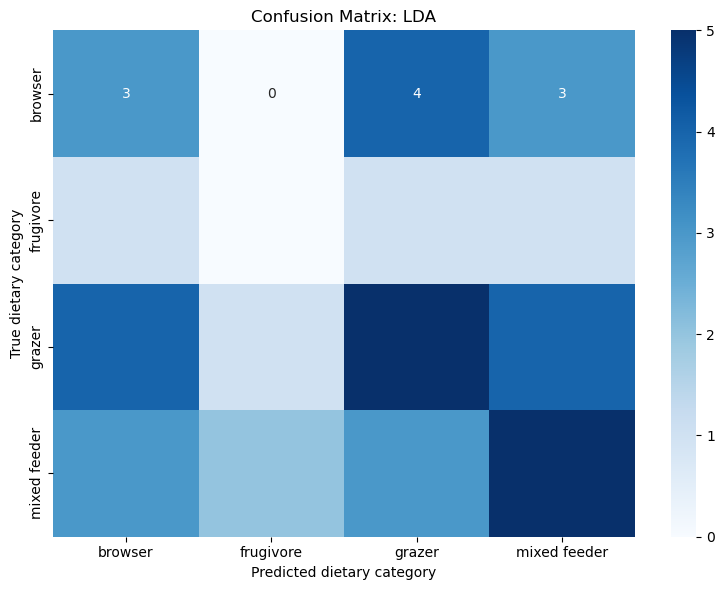

Saved: ../../results/lda/lda_confusion_matrix.png


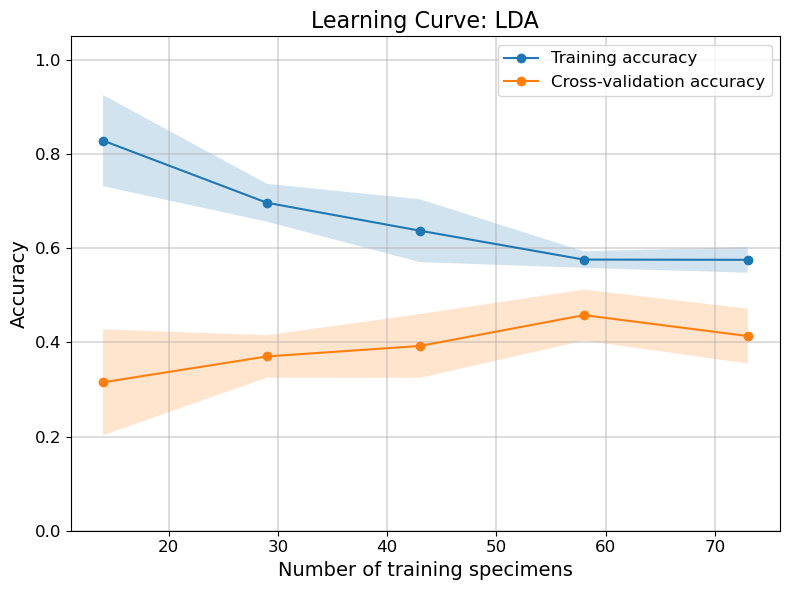

Saved: ../../results/lda/lda_learning_curve.png
Saved: ../../results/lda/lda_learning_curve_values.csv


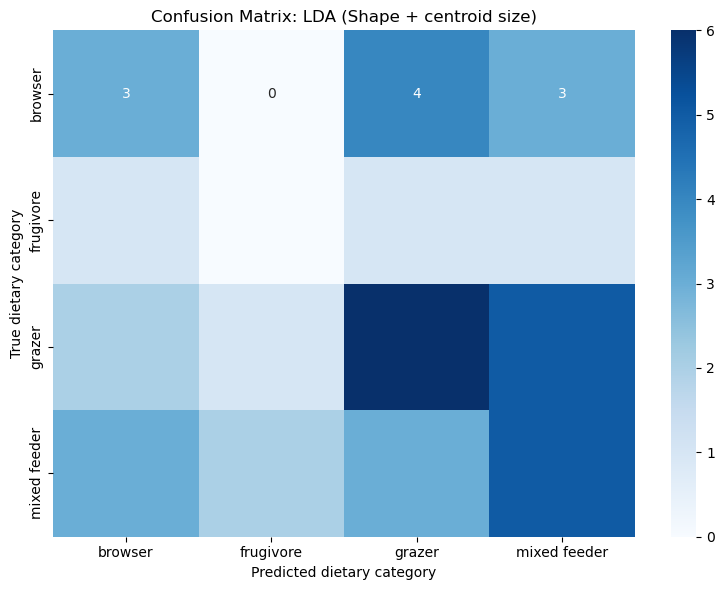

Saved: ../../results/lda/lda_shape_cs_confusion_matrix.png


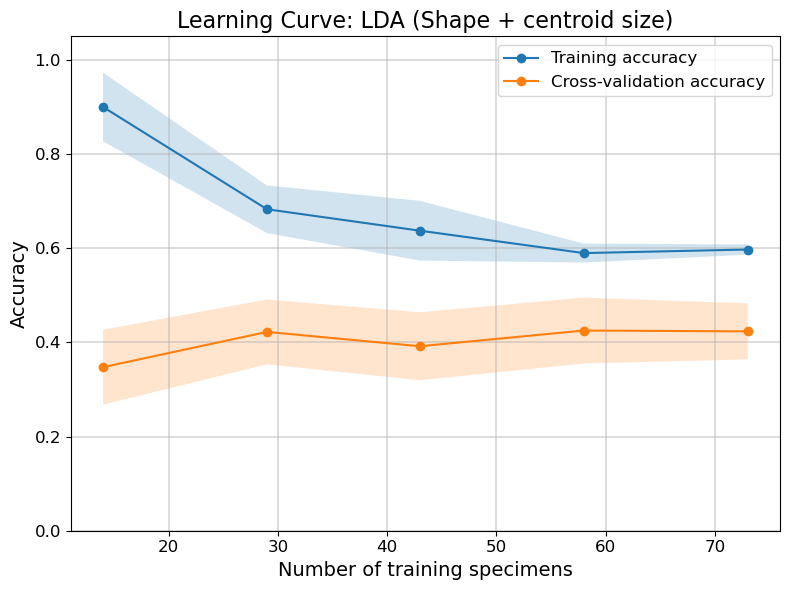

Saved: ../../results/lda/lda_shape_cs_learning_curve.png
Saved: ../../results/lda/lda_shape_cs_learning_curve_values.csv


In [51]:
# -----------------------------
# Save confusion matrix and learning curve plots
# -----------------------------

plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Confusion Matrix: LDA")
plt.xlabel("Predicted dietary category")
plt.ylabel("True dietary category")
plt.tight_layout()

confusion_plot_path = OUTPUT_DIR / "lda_confusion_matrix.png"
plt.savefig(confusion_plot_path, dpi=300)
plt.show()
print(f"Saved: {confusion_plot_path}")


# Learning curve:
# This shows how training and cross-validation accuracy change as training
# sample size increases. A large gap between the two lines can indicate overfitting.

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=lda_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    train_sizes=np.linspace(0.2, 1.0, 5),
)

learning_curve_df = pd.DataFrame({
    "train_size": train_sizes,
    "train_score_mean": train_scores.mean(axis=1),
    "train_score_sd": train_scores.std(axis=1),
    "validation_score_mean": validation_scores.mean(axis=1),
    "validation_score_sd": validation_scores.std(axis=1),
})

plt.figure(figsize=(8, 6))
plt.plot(
    learning_curve_df["train_size"],
    learning_curve_df["train_score_mean"],
    marker="o",
    label="Training accuracy",
)
plt.fill_between(
    learning_curve_df["train_size"],
    learning_curve_df["train_score_mean"] - learning_curve_df["train_score_sd"],
    learning_curve_df["train_score_mean"] + learning_curve_df["train_score_sd"],
    alpha=0.2,
)
plt.plot(
    learning_curve_df["train_size"],
    learning_curve_df["validation_score_mean"],
    marker="o",
    label="Cross-validation accuracy",
)
plt.fill_between(
    learning_curve_df["train_size"],
    learning_curve_df["validation_score_mean"] - learning_curve_df["validation_score_sd"],
    learning_curve_df["validation_score_mean"] + learning_curve_df["validation_score_sd"],
    alpha=0.2,
)
plt.title(f"Learning Curve: LDA", fontsize = 16)
plt.xlabel("Number of training specimens", fontsize = 14)
plt.ylabel("Accuracy", fontsize = 14)
plt.ylim(0, 1.05)
plt.tick_params(axis = "both", labelsize = 12)
plt.legend(prop = {"size": 12})
plt.grid(True, linewidth = 1.2, alpha=0.5)
plt.tight_layout()

learning_curve_plot_path = OUTPUT_DIR / "lda_learning_curve.png"
plt.savefig(learning_curve_plot_path, dpi=400)
plt.show()
print(f"Saved: {learning_curve_plot_path}")

learning_curve_values_path = OUTPUT_DIR / "lda_learning_curve_values.csv"
learning_curve_df.to_csv(learning_curve_values_path, index=False)
print(f"Saved: {learning_curve_values_path}") 

# Confusion matrix: Shape + centroid size
conf_matrix_cs = confusion_matrix(y_test, y_test_pred_cs, labels=class_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix_cs,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Confusion Matrix: LDA (Shape + centroid size)")
plt.xlabel("Predicted dietary category")
plt.ylabel("True dietary category")
plt.tight_layout()

conf_cs_plot_path = OUTPUT_DIR / "lda_shape_cs_confusion_matrix.png"
plt.savefig(conf_cs_plot_path, dpi=300)
plt.show()
print(f"Saved: {conf_cs_plot_path}")


#### 
# Learning curve: Shape + centroid size
train_sizes_cs, train_scores_cs, validation_scores_cs = learning_curve(
    estimator=shape_cs_pipeline,
    X=X_train_cs,
    y=y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    train_sizes=np.linspace(0.2, 1.0, 5),
)

learning_curve_cs_df = pd.DataFrame({
    "train_size": train_sizes_cs,
    "train_score_mean": train_scores_cs.mean(axis=1),
    "train_score_sd": train_scores_cs.std(axis=1),
    "validation_score_mean": validation_scores_cs.mean(axis=1),
    "validation_score_sd": validation_scores_cs.std(axis=1),
})

plt.figure(figsize=(8, 6))
plt.plot(learning_curve_cs_df["train_size"], learning_curve_cs_df["train_score_mean"],
         marker="o", label="Training accuracy")
plt.fill_between(
    learning_curve_cs_df["train_size"],
    learning_curve_cs_df["train_score_mean"] - learning_curve_cs_df["train_score_sd"],
    learning_curve_cs_df["train_score_mean"] + learning_curve_cs_df["train_score_sd"],
    alpha=0.2,
)
plt.plot(learning_curve_cs_df["train_size"], learning_curve_cs_df["validation_score_mean"],
         marker="o", label="Cross-validation accuracy")
plt.fill_between(
    learning_curve_cs_df["train_size"],
    learning_curve_cs_df["validation_score_mean"] - learning_curve_cs_df["validation_score_sd"],
    learning_curve_cs_df["validation_score_mean"] + learning_curve_cs_df["validation_score_sd"],
    alpha=0.2,
)
plt.title("Learning Curve: LDA (Shape + centroid size)", fontsize=16)
plt.xlabel("Number of training specimens", fontsize=14)
plt.ylabel("Accuracy", fontsize=14)
plt.ylim(0, 1.05)
plt.tick_params(axis="both", labelsize=12)
plt.legend(prop={"size": 12})
plt.grid(True, linewidth=1.2, alpha=0.5)
plt.tight_layout()

lc_cs_plot_path = OUTPUT_DIR / "lda_shape_cs_learning_curve.png"
plt.savefig(lc_cs_plot_path, dpi=400)
plt.show()
print(f"Saved: {lc_cs_plot_path}")

lc_cs_values_path = OUTPUT_DIR / "lda_shape_cs_learning_curve_values.csv"
learning_curve_cs_df.to_csv(lc_cs_values_path, index=False)
print(f"Saved: {lc_cs_values_path}")
  


## 11. Optional 2D decision-region visualization

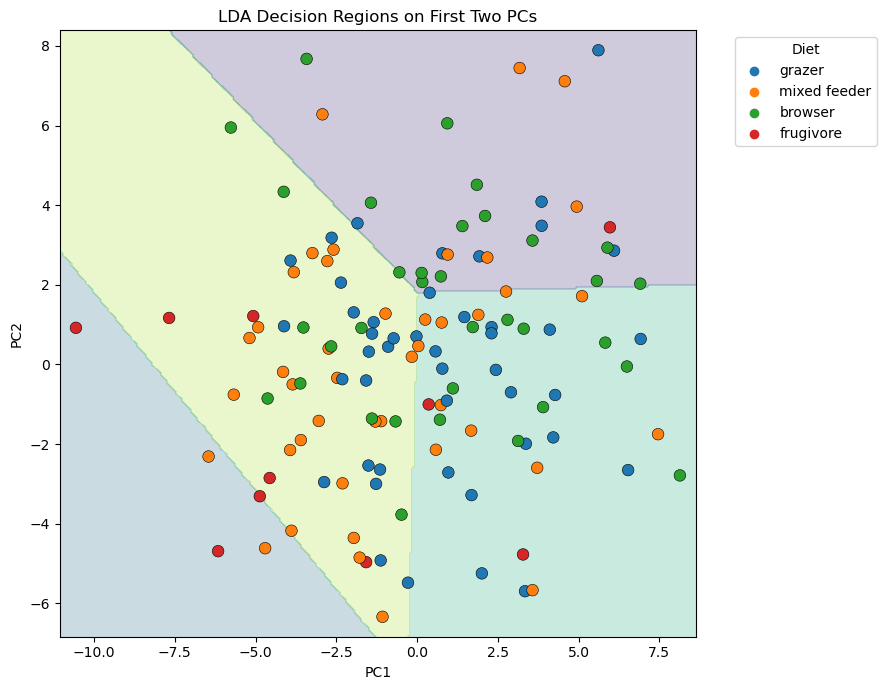

Saved: ../../results/lda/lda_decision_regions_PC1_PC2_visualization.png


In [29]:
# -----------------------------
# Optional 2D LDA decision-region plot
# -----------------------------

# This plot is for visualization only.
# It fits a separate PCA(2) + LDA pipeline so that the decision regions can be
# displayed in two dimensions. It is not used for the main performance metrics
# unless PCA_N_COMPONENTS is also set to 2.

if len(label_encoder.classes_) >= 2:
    lda_2d_pipeline = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=2)),
            ("lda", LinearDiscriminantAnalysis()),
        ]
    )

    lda_2d_pipeline.fit(X_train, y_train)

    X_all_2d = lda_2d_pipeline.named_steps["pca"].transform(
        lda_2d_pipeline.named_steps["scaler"].transform(X)
    )

    x_min, x_max = X_all_2d[:, 0].min() - 0.5, X_all_2d[:, 0].max() + 0.5
    y_min, y_max = X_all_2d[:, 1].min() - 0.5, X_all_2d[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )

    Z = lda_2d_pipeline.named_steps["lda"].predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plot_df = pd.DataFrame({
        "PC1": X_all_2d[:, 0],
        "PC2": X_all_2d[:, 1],
        "Diet": label_encoder.inverse_transform(y),
    })

    plt.figure(figsize=(9, 7))
    plt.contourf(xx, yy, Z, alpha=0.25, levels=np.arange(len(label_encoder.classes_) + 1) - 0.5)
    sns.scatterplot(
        data=plot_df,
        x="PC1",
        y="PC2",
        hue="Diet",
        s=70,
        edgecolor="black",
        linewidth=0.4,
    )
    plt.title("LDA Decision Regions on First Two PCs")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend(title="Diet", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    decision_plot_path = OUTPUT_DIR / "lda_decision_regions_PC1_PC2_visualization.png"
    plt.savefig(decision_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {decision_plot_path}")
else:
    print("Decision-region plot skipped because fewer than two classes were detected.")


## 13. Discriminant axis plot and deformation grids

This section provides a more explicit, biologically interpretable graphical
output for the LDA/discriminant function analysis:

1. **Discriminant axis plot** -- specimens plotted on the actual canonical/
   discriminant function axes (DF1 vs. DF2), not on the PC1/PC2 axes used
   elsewhere in this notebook. Group centroids are shown, and misclassified
   test-set specimens are marked.
2. **Deformation grids** -- thin-plate spline (TPS) grids showing the shape
   change associated with moving along each discriminant axis, visualized at
   +/- 2 SD from the sample mean score on that axis. This is what makes a
   discriminant axis biologically interpretable: it shows *what shape change*
   separates the groups, not just how well they classify.


Number of discriminant axes available: 3 (min(n_classes - 1, n_pcs) = min(3, 6))


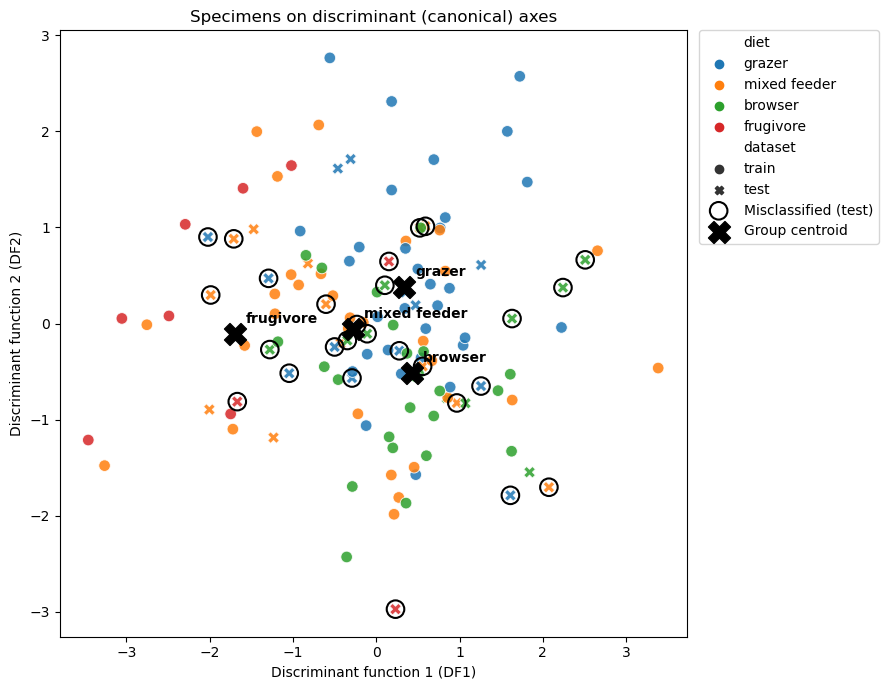

Saved: ../../results/lda/lda_discriminant_axis_plot.png


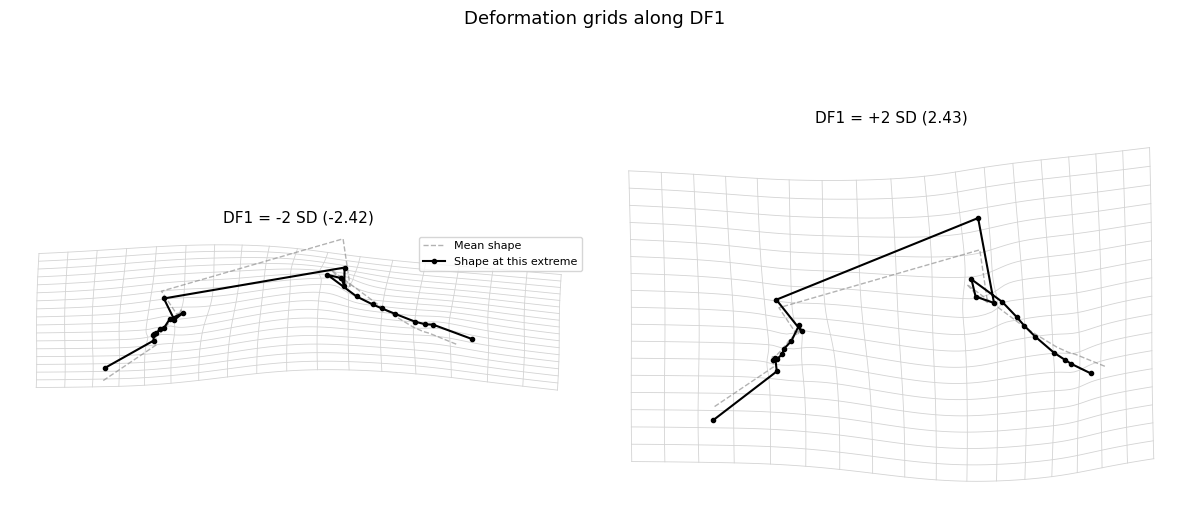

Saved: ../../results/lda/lda_deformation_grid_df1.png


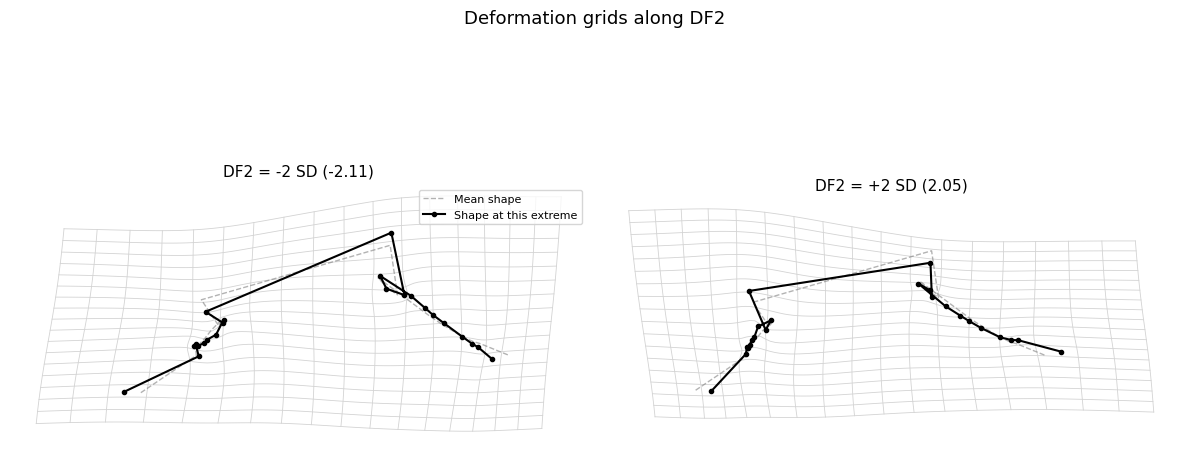

Saved: ../../results/lda/lda_deformation_grid_df2.png
Note: 3 discriminant axes exist in total; only the first 2 are shown above. Additional axes can be plotted the same way by extending `n_axes_to_plot`.


In [31]:
# -----------------------------
# Discriminant axis plot and deformation grids
# -----------------------------

# -----------------------------
# 1. Discriminant (canonical) axis scores
# -----------------------------
# lda_pipeline = Pipeline([scaler, pca, lda]). Because LinearDiscriminantAnalysis
# implements .transform() (projection onto the discriminant axes), calling
# .transform() on the whole pipeline chains StandardScaler -> PCA -> LDA and
# returns canonical/discriminant scores, NOT PCA scores.
ld_scores_all = lda_pipeline.transform(X)
n_ld_axes = ld_scores_all.shape[1]
ld_axis_names = [f"DF{i + 1}" for i in range(n_ld_axes)]

print(f"Number of discriminant axes available: {n_ld_axes} "
      f"(min(n_classes - 1, n_pcs) = min({len(label_encoder.classes_) - 1}, {SELECTED_N_PCS}))")

ld_scores_df = pd.DataFrame(ld_scores_all, columns=ld_axis_names)
ld_scores_df["diet"] = label_encoder.inverse_transform(y)
ld_scores_df["dataset"] = np.where(np.isin(data.index, train_indices), "train", "test")

# Flag misclassified test-set specimens for the plot.
test_correct_lookup = pd.Series(
    (y_test == y_test_pred),
    index=test_indices,
)
ld_scores_df["test_correct"] = ld_scores_df.index.map(test_correct_lookup).astype("boolean")

# -----------------------------
# Plot: specimens on discriminant axes
# -----------------------------
if n_ld_axes >= 2:
    plt.figure(figsize=(9, 7))
    sns.scatterplot(
        data=ld_scores_df,
        x="DF1",
        y="DF2",
        hue="diet",
        style="dataset",
        s=70,
        alpha=0.85,
    )

    # Mark misclassified test-set specimens with a black outline.
    misclassified = ld_scores_df[ld_scores_df["test_correct"] == False]  # noqa: E712
    if len(misclassified) > 0:
        plt.scatter(
            misclassified["DF1"],
            misclassified["DF2"],
            facecolors="none",
            edgecolors="black",
            s=160,
            linewidths=1.5,
            label="Misclassified (test)",
        )

    # Group centroids.
    centroids = ld_scores_df.groupby("diet")[["DF1", "DF2"]].mean()
    plt.scatter(
        centroids["DF1"],
        centroids["DF2"],
        marker="X",
        s=250,
        c="black",
        label="Group centroid",
        zorder=5,
    )
    for diet_label, row in centroids.iterrows():
        plt.annotate(
            diet_label,
            (row["DF1"], row["DF2"]),
            textcoords="offset points",
            xytext=(8, 8),
            fontsize=10,
            fontweight="bold",
        )

    plt.xlabel("Discriminant function 1 (DF1)")
    plt.ylabel("Discriminant function 2 (DF2)")
    plt.title("Specimens on discriminant (canonical) axes")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
    plt.tight_layout()

    df_axis_plot_path = OUTPUT_DIR / "lda_discriminant_axis_plot.png"
    plt.savefig(df_axis_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {df_axis_plot_path}")

else:
    # Only one discriminant axis exists (two-class problem): show a 1D strip/
    # distribution plot instead of a 2D scatter.
    plt.figure(figsize=(9, 5))
    sns.stripplot(data=ld_scores_df, x="DF1", y="diet", hue="dataset", jitter=0.25, size=7)
    for diet_label, group in ld_scores_df.groupby("diet"):
        plt.axvline(group["DF1"].mean(), linestyle="--", linewidth=1, alpha=0.7)
    plt.xlabel("Discriminant function 1 (DF1)")
    plt.title("Specimens on the single discriminant axis (DF1)")
    plt.tight_layout()

    df_axis_plot_path = OUTPUT_DIR / "lda_discriminant_axis_plot.png"
    plt.savefig(df_axis_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {df_axis_plot_path}")

# -----------------------------
# 2. Deformation grids (thin-plate spline)
# -----------------------------
# Standard geometric morphometric approach for visualizing what a
# discriminant axis "means" biologically:
#   a) Compute the sample mean (consensus) shape from the Procrustes-aligned
#      coordinates already loaded as X.
#   b) For each discriminant axis, regress the raw shape coordinates on the
#      discriminant score (a simple per-coordinate OLS against one predictor,
#      i.e. a "shape regression" / regression score approach).
#   c) Predict the shape at +/- 2 SD from the mean score on that axis.
#   d) Warp a reference grid from the mean shape to each predicted extreme
#      shape using a thin-plate spline (TPS), and plot the warped grid plus
#      the (connected, in landmark order) target shape outline.

n_landmarks = len(coordinate_columns) // 2
mean_shape_flat = X[coordinate_columns].mean(axis=0).to_numpy()
mean_shape = mean_shape_flat.reshape(n_landmarks, 2)


def _tps_weights(source: np.ndarray, target: np.ndarray) -> np.ndarray:
    """
    Solve for thin-plate spline weights warping `source` landmarks onto
    `target` landmarks. Returns an (n_landmarks + 3, 2) array: the first
    n_landmarks rows are the non-affine weights, the last 3 rows are the
    affine coefficients [a1, ax, ay] for x and y separately.
    """
    n = source.shape[0]
    diff = source[:, None, :] - source[None, :, :]
    r2 = np.sum(diff ** 2, axis=-1)
    with np.errstate(divide="ignore", invalid="ignore"):
        K = r2 * np.log(r2)
    K = np.nan_to_num(K, nan=0.0)

    P = np.hstack([np.ones((n, 1)), source])
    L = np.zeros((n + 3, n + 3))
    L[:n, :n] = K
    L[:n, n:] = P
    L[n:, :n] = P.T

    Y = np.zeros((n + 3, 2))
    Y[:n, :] = target

    weights = np.linalg.solve(L, Y)
    return weights


def _tps_warp_points(points: np.ndarray, source: np.ndarray, weights: np.ndarray) -> np.ndarray:
    """Warp arbitrary points using TPS weights fit from `source` landmarks."""
    n = source.shape[0]
    w = weights[:n]
    a = weights[n:]

    diff = points[:, None, :] - source[None, :, :]
    r2 = np.sum(diff ** 2, axis=-1)
    with np.errstate(divide="ignore", invalid="ignore"):
        U = r2 * np.log(r2)
    U = np.nan_to_num(U, nan=0.0)

    affine = a[0] + points @ a[1:]
    nonaffine = U @ w
    return affine + nonaffine


def _make_reference_grid(landmarks: np.ndarray, margin: float = 0.2, n_lines: int = 18, n_points: int = 100):
    """Build a regular grid of line segments spanning the landmarks' bounding box."""
    x_min, y_min = landmarks.min(axis=0)
    x_max, y_max = landmarks.max(axis=0)
    x_pad = (x_max - x_min) * margin
    y_pad = (y_max - y_min) * margin
    x_min, x_max = x_min - x_pad, x_max + x_pad
    y_min, y_max = y_min - y_pad, y_max + y_pad

    lines = []
    for x in np.linspace(x_min, x_max, n_lines):
        ys = np.linspace(y_min, y_max, n_points)
        lines.append(np.column_stack([np.full_like(ys, x), ys]))
    for y in np.linspace(y_min, y_max, n_lines):
        xs = np.linspace(x_min, x_max, n_points)
        lines.append(np.column_stack([xs, np.full_like(xs, y)]))
    return lines


def plot_deformation_grid(ax, source_landmarks, target_landmarks, title):
    grid_lines = _make_reference_grid(source_landmarks)
    weights = _tps_weights(source_landmarks, target_landmarks)

    for line in grid_lines:
        warped = _tps_warp_points(line, source_landmarks, weights)
        ax.plot(warped[:, 0], warped[:, 1], color="lightgray", linewidth=0.6, zorder=1)

    # Reference (mean) shape outline, thin and dashed, for comparison.
    # Drawn as an open curve (landmark 1 → 23) — not closed back to start,
    # since this is a cusp outline, not a closed polygon.
    ax.plot(
        source_landmarks[:, 0],
        source_landmarks[:, 1],
        linestyle="--", linewidth=1, color="gray", alpha=0.6, zorder=2,
        label="Mean shape",
    )

    # Target (warped/extreme) shape outline — open curve, same order.
    ax.plot(
        target_landmarks[:, 0],
        target_landmarks[:, 1],
        marker="o", markersize=3, linewidth=1.5, color="black", zorder=3,
        label="Shape at this extreme",
    )

    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")
    ax.axis("off")


n_axes_to_plot = min(n_ld_axes, 2)  # DF1, and DF2 if it exists
X_coords_only = X[coordinate_columns].to_numpy()

for axis_idx in range(n_axes_to_plot):
    scores = ld_scores_all[:, axis_idx]
    score_mean = scores.mean()
    score_sd = scores.std()

    # Per-coordinate simple linear regression of shape on this axis's score
    # (equivalent to a multivariate regression with a single predictor).
    slopes = np.array([
        np.polyfit(scores, X_coords_only[:, c], deg=1)[0]
        for c in range(X_coords_only.shape[1])
    ])

    negative_score = score_mean - 2 * score_sd
    positive_score = score_mean + 2 * score_sd

    negative_shape = (mean_shape_flat + slopes * (negative_score - score_mean)).reshape(n_landmarks, 2)
    positive_shape = (mean_shape_flat + slopes * (positive_score - score_mean)).reshape(n_landmarks, 2)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    plot_deformation_grid(
        axes[0], mean_shape, negative_shape,
        title=f"{ld_axis_names[axis_idx]} = -2 SD ({negative_score:.2f})",
    )
    plot_deformation_grid(
        axes[1], mean_shape, positive_shape,
        title=f"{ld_axis_names[axis_idx]} = +2 SD ({positive_score:.2f})",
    )
    axes[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(f"Deformation grids along {ld_axis_names[axis_idx]}", fontsize=13)
    plt.tight_layout()

    deformation_plot_path = OUTPUT_DIR / f"lda_deformation_grid_{ld_axis_names[axis_idx].lower()}.png"
    plt.savefig(deformation_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {deformation_plot_path}")

if n_ld_axes > 2:
    print(
        f"Note: {n_ld_axes} discriminant axes exist in total; only the first "
        f"{n_axes_to_plot} are shown above. Additional axes can be plotted the "
        "same way by extending `n_axes_to_plot`."
    )


## 12. Output summary

In [ ]:
# -----------------------------
# Final output summary
# -----------------------------

print("LDA workflow complete.")
print(f"\nOutputs saved to: {OUTPUT_DIR.resolve()}")
print("\nOutput files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(f"- {path.name}")
